#Tests for .in files

##MSD visualizer

50 organelles, 201 frames, lag up to 2000.0 tau
mitochondrion   n =  30  alpha = 1.134  D_sim = 0.002773 r_c^2/tau
vesicle         n =  20  alpha = 1.038  D_sim = 0.00306 r_c^2/tau


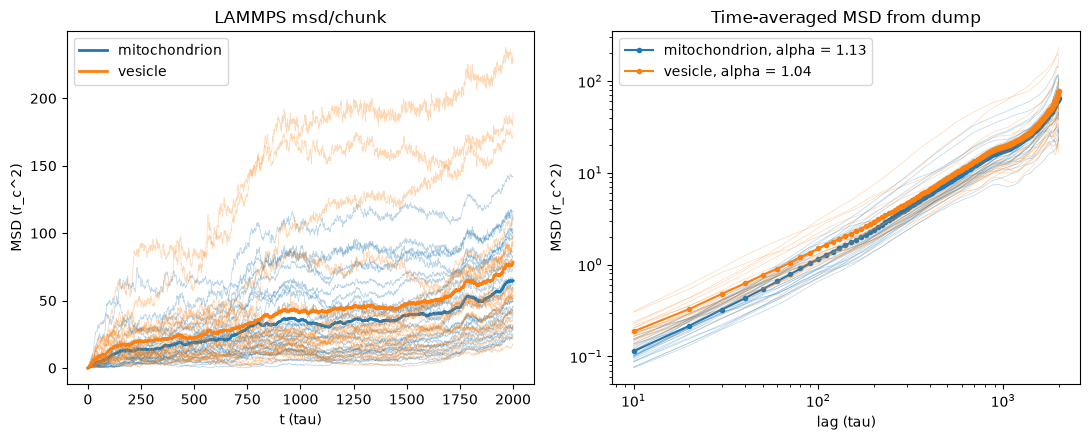

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
RUN_DIR = CODE_DIR / "test_run"
GRAPHS_DIR = CODE_DIR.parent / "graphs"

DT = 0.01        # must match `timestep` in the input script

# Settings
run = RUN_DIR    # run folder with msd_mito.dat and dump.m1
RC_UM = 0.25     # bead size r_c in micrometres
FIT_FROM = 0.01   # fit lags above this fraction of the longest lag
TAU_S = None     # DPD time unit in seconds (after calibration)

from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

NAME = "m1_crowded_mix"   # in_name you gave Run(...)

names = read_type_names(run / f"{NAME}.data")
steps, msd_lmp = read_msd_dat(run / "msd_org_crowded.dat")
t_lmp = steps * DT
dsteps, com, mol_ids, types = read_dump_com_typed(run / f"dump.{NAME}")
lags, msd_all, per_org = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT
late = t >= FIT_FROM * t[-1]
msd_lmp = msd_lmp[:, mol_ids - 1]   # chunk ID = molecule ID, so columns line up with com

print(f"{com.shape[1]} organelles, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
results = {}
for k, ty in enumerate(np.unique(types)):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org[:, sel].mean(axis=1)
    alpha, _ = fit_power_law(t[late], msd[late])
    D_sim = np.polyfit(t[late], msd[late], 1)[0] / 6
    results[name] = (alpha, D_sim)
    line = f"{name:15s} n = {sel.sum():3d}  alpha = {alpha:.3f}  D_sim = {D_sim:.4g} r_c^2/tau"
    if TAU_S:
        line += f"  D = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s"
    print(line)
    ax[0].plot(t_lmp, msd_lmp[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_lmp, msd_lmp[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t, per_org[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[1].loglog(t, msd, "o-", color=color, ms=3, label=f"{name}, alpha = {alpha:.2f}")
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump")
ax[0].legend(); ax[1].legend()
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / f"{NAME}_msd.png", dpi=150)

In [5]:
from utilities import Run, Type

run = Run("test_run", "m1_crowded_mix", [20, 20, 8])
run.add_type(Type("mitochondrion", 30, "capsule", r=1.0, l=8.0, rel_density=1.1))
run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
run.fill_cytoplasm(3.0)
run.write_data_file()
run.write_input_file(steps=200000, dump_every=1000, thermo_every=1000)